In [2]:

!pip -q install pandas numpy scikit-learn matplotlib seaborn langdetect joblib

import pandas as pd
import numpy as np
import requests
import io
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("TurkmenAI environment initialized!")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
TurkmenAI environment initialized!


In [3]:

# TURKMENAI — DATA COLLECTION

BASE_URL = "https://downloads.tatoeba.org/exports/per_language/"

LANGUAGES = {
    "tuk": "Turkmen",
    "tur": "Turkish",
    "aze": "Azerbaijani",
    "eng": "English",
    "rus": "Russian"
}

frames = []

for code, language in LANGUAGES.items():

    url = f"{BASE_URL}{code}/{code}_sentences.tsv.bz2"

    print("Downloading:", language)

    response = requests.get(url, timeout=120)
    response.raise_for_status()

    data = pd.read_csv(
        io.BytesIO(response.content),
        sep="\t",
        header=None,
        names=["id", "code", "text"],
        usecols=[0, 1, 2],
        compression="bz2",
        dtype=str,
        on_bad_lines="skip"
    )

    data["language"] = language
    frames.append(data)

df = pd.concat(frames, ignore_index=True)

df = df.dropna(subset=["text"])
df["text"] = df["text"].str.strip()
df = df[df["text"].str.len() >= 3]
df = df.drop_duplicates(subset=["language", "text"])

print("\nDATASET LOADED")
print(df.groupby("language").size())
print("\nTotal sentences:", len(df))

Downloading: Turkmen
Downloading: Turkish
Downloading: Azerbaijani
Downloading: English
Downloading: Russian

DATASET LOADED
language
Azerbaijani      12856
English        2038757
Russian        1237522
Turkish         747621
Turkmen           7264
dtype: int64

Total sentences: 4044020


In [4]:

# TURKMENAI — BALANCED DATASET

SAMPLES_PER_LANGUAGE = 7000

balanced_df = (
    df.groupby("language", group_keys=False)
      .sample(
          n=SAMPLES_PER_LANGUAGE,
          random_state=42
      )
      .reset_index(drop=True)
)

print("Balanced dataset:")
print(balanced_df["language"].value_counts())

print("\nTotal:", len(balanced_df))

# Shuffle dataset
balanced_df = balanced_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

Balanced dataset:
language
Azerbaijani    7000
English        7000
Russian        7000
Turkish        7000
Turkmen        7000
Name: count, dtype: int64

Total: 35000


In [5]:

# TRAIN / TEST SPLIT

X = balanced_df["text"]
y = balanced_df["language"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 28000
Testing samples: 7000


In [6]:

# TURKMENAI — MODEL TRAINING

vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(1, 3),
    max_features=100000,
    min_df=2,
    sublinear_tf=True
)

X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_vec, y_train)

print("TurkmenAI model training completed!")

TurkmenAI model training completed!


TURKMENAI ACCURACY: 98.89 %

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

 Azerbaijani       0.98      0.97      0.98      1400
     English       1.00      1.00      1.00      1400
     Russian       1.00      1.00      1.00      1400
     Turkish       0.98      0.98      0.98      1400
     Turkmen       0.99      0.99      0.99      1400

    accuracy                           0.99      7000
   macro avg       0.99      0.99      0.99      7000
weighted avg       0.99      0.99      0.99      7000



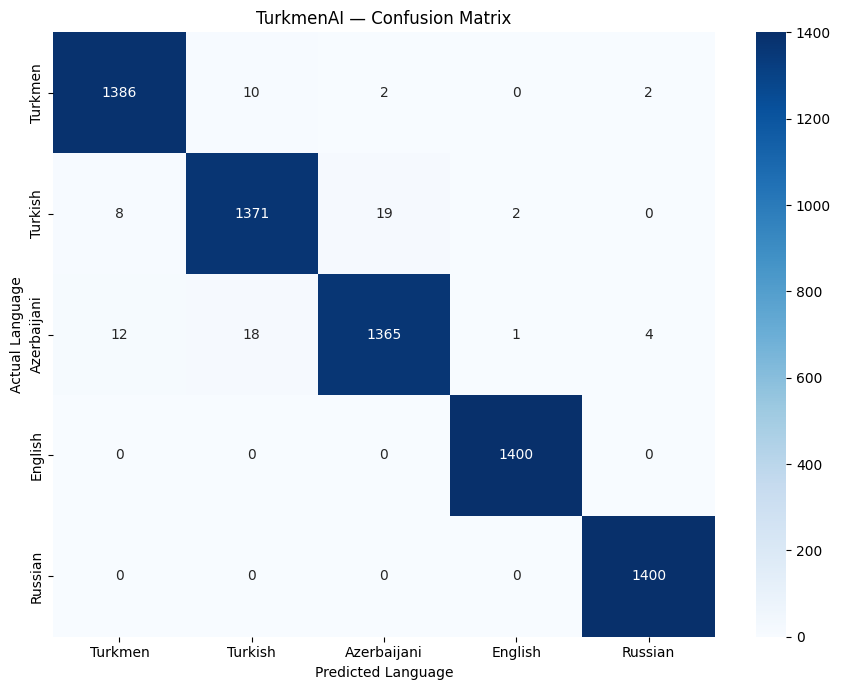

In [7]:

# MODEL EVALUATION

y_pred = model.predict(X_test_vec)

accuracy = accuracy_score(y_test, y_pred)

print("TURKMENAI ACCURACY:", round(accuracy * 100, 2), "%")

print("\nCLASSIFICATION REPORT:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=list(LANGUAGES.values())
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=LANGUAGES.values(),
    yticklabels=LANGUAGES.values()
)

plt.title("TurkmenAI — Confusion Matrix")
plt.xlabel("Predicted Language")
plt.ylabel("Actual Language")
plt.tight_layout()
plt.show()

In [8]:

# TURKMENAI — TURKMEN-SPECIFIC ANALYSIS

from sklearn.metrics import accuracy_score

turkmen_mask = (y_test == "Turkmen")

turkmen_true = y_test[turkmen_mask]
turkmen_pred = y_pred[turkmen_mask]

turkmen_accuracy = accuracy_score(
    turkmen_true,
    turkmen_pred
)

print("TURKMEN LANGUAGE ACCURACY:",
      round(turkmen_accuracy * 100, 2), "%")

print("\nTurkmen test samples:",
      len(turkmen_true))

print("\nCorrect predictions:",
      (turkmen_true == turkmen_pred).sum())

print("\nIncorrect predictions:",
      (turkmen_true != turkmen_pred).sum())

TURKMEN LANGUAGE ACCURACY: 99.0 %

Turkmen test samples: 1400

Correct predictions: 1386

Incorrect predictions: 14


In [9]:

# TURKMENAI — LIVE PREDICTION

def detect_language(text):
    vector = vectorizer.transform([text])
    prediction = model.predict(vector)[0]

    probabilities = model.predict_proba(vector)[0]
    confidence = max(probabilities) * 100

    return {
        "text": text,
        "language": prediction,
        "confidence": round(confidence, 2)
    }

test_sentences = [
    "Salam, men Türkmenistanda ýaşaýaryn.",
    "Men bugün täze kitap okadym.",
    "Merhaba, bugün nasılsın?",
    "Hello, how are you today?",
    "Привет, как твои дела?",
    "Salam, bugün nähili?"
]

for sentence in test_sentences:
    print(detect_language(sentence))

{'text': 'Salam, men Türkmenistanda ýaşaýaryn.', 'language': 'Turkmen', 'confidence': np.float64(98.24)}
{'text': 'Men bugün täze kitap okadym.', 'language': 'Turkmen', 'confidence': np.float64(97.39)}
{'text': 'Merhaba, bugün nasılsın?', 'language': 'Turkish', 'confidence': np.float64(85.6)}
{'text': 'Hello, how are you today?', 'language': 'English', 'confidence': np.float64(97.03)}
{'text': 'Привет, как твои дела?', 'language': 'Russian', 'confidence': np.float64(99.07)}
{'text': 'Salam, bugün nähili?', 'language': 'Turkmen', 'confidence': np.float64(66.94)}


In [10]:

# TURKMENAI — BASELINE COMPARISON

from langdetect import detect, DetectorFactory
from langdetect.lang_detect_exception import LangDetectException

DetectorFactory.seed = 42

supported = {
    "Turkish": "tr",
    "Azerbaijani": "az",
    "English": "en",
    "Russian": "ru"
}

results = []

for text, actual in zip(X_test, y_test):

    if actual not in supported:
        continue

    try:
        baseline_prediction = detect(text)
    except LangDetectException:
        baseline_prediction = "unknown"

    our_prediction = model.predict(
        vectorizer.transform([text])
    )[0]

    results.append({
        "actual": actual,
        "TurkmenAI": our_prediction,
        "langdetect": baseline_prediction,
        "TurkmenAI_correct": our_prediction == actual,
        "baseline_correct": baseline_prediction == supported[actual]
    })

comparison = pd.DataFrame(results)

print("TurkmenAI accuracy:",
      round(comparison["TurkmenAI_correct"].mean() * 100, 2), "%")

print("langdetect accuracy:",
      round(comparison["baseline_correct"].mean() * 100, 2), "%")

print("\nPer-language comparison:")

for language in supported:
    subset = comparison[comparison["actual"] == language]

    print(
        language,
        "| TurkmenAI:",
        round(subset["TurkmenAI_correct"].mean() * 100, 2),
        "%",
        "| langdetect:",
        round(subset["baseline_correct"].mean() * 100, 2),
        "%"
    )

print("\nTurkmen language:")
print("langdetect does not have a standard Turkmen profile.")

TurkmenAI accuracy: 98.86 %
langdetect accuracy: 70.43 %

Per-language comparison:
Turkish | TurkmenAI: 97.93 % | langdetect: 97.14 %
Azerbaijani | TurkmenAI: 97.5 % | langdetect: 0.0 %
English | TurkmenAI: 100.0 % | langdetect: 92.71 %
Russian | TurkmenAI: 100.0 % | langdetect: 91.86 %

Turkmen language:
langdetect does not have a standard Turkmen profile.


In [11]:

# TURKMENAI — ERROR ANALYSIS

errors = pd.DataFrame({
    "text": X_test.reset_index(drop=True),
    "actual": y_test.reset_index(drop=True),
    "predicted": pd.Series(y_pred)
})

errors = errors[
    errors["actual"] != errors["predicted"]
]

print("Total errors:", len(errors))
display(errors.head(20))

Total errors: 78


,text,actual,predicted
103,Tom's worried.,Azerbaijani,English
194,"Merhaba, baba.",Turkish,Turkmen
430,Sat!,Azerbaijani,Turkmen
435,Tom 333 oy aldı.,Turkish,Azerbaijani
459,Tom parka getdi.,Azerbaijani,Turkmen
578,Biz hepimiz onu gördük.,Turkish,Azerbaijani
674,Dur!,Turkish,Azerbaijani
772,Salam!,Turkmen,Azerbaijani
804,Öl.,Azerbaijani,Turkmen
999,Tanrı öldü. Onu biz öldürdük.,Azerbaijani,Turkish


In [14]:
# TURKMENAI — ERROR CATEGORY ANALYSIS

def categorize_error(row):
    text = str(row["text"])

    if len(text.split()) <= 2:
        return "Short text"

    if any(ch in text for ch in "әөүҗңқғһі"):
        return "Special Cyrillic characters"

    if any(ch in text for ch in "ğışçöü"):
        return "Turkic Latin characters"

    return "Similar vocabulary / Other"

errors["error_category"] = errors.apply(
    categorize_error, axis=1
)

print("ERROR CATEGORY DISTRIBUTION:")
print(errors["error_category"].value_counts())

print("\nERRORS BY ACTUAL LANGUAGE:")
print(errors["actual"].value_counts())

print("\nERRORS BY PREDICTED LANGUAGE:")
print(errors["predicted"].value_counts())

ERROR CATEGORY DISTRIBUTION:
error_category
Short text                     34
Turkic Latin characters        29
Similar vocabulary / Other     10
Special Cyrillic characters     5
Name: count, dtype: int64

ERRORS BY ACTUAL LANGUAGE:
actual
Azerbaijani    35
Turkish        29
Turkmen        14
Name: count, dtype: int64

ERRORS BY PREDICTED LANGUAGE:
predicted
Turkish        28
Azerbaijani    21
Turkmen        20
Russian         6
English         3
Name: count, dtype: int64


In [15]:
# TURKMENAI — SMART CONFIDENCE SYSTEM

def smart_detect_language(text):
    vector = vectorizer.transform([text])

    probabilities = model.predict_proba(vector)[0]

    best_index = np.argmax(probabilities)

    prediction = model.classes_[best_index]
    confidence = probabilities[best_index] * 100

    if len(text.split()) <= 2:
        status = "Insufficient text — more words needed"

    elif confidence >= 90:
        status = "High confidence"

    elif confidence >= 70:
        status = "Medium confidence"

    else:
        status = "Low confidence — verify result"

    return {
        "Text": text,
        "Predicted language": prediction,
        "Confidence": round(float(confidence), 2),
        "Status": status
    }


examples = [
    "Salam, men Türkmenistanda ýaşaýaryn.",
    "Merhaba, bugün nasılsın?",
    "Salam!",
    "Men täze matematika meselesini çözýärin."
]

for sentence in examples:
    print(smart_detect_language(sentence))
    print("-" * 50)

{'Text': 'Salam, men Türkmenistanda ýaşaýaryn.', 'Predicted language': 'Turkmen', 'Confidence': 98.24, 'Status': 'High confidence'}
--------------------------------------------------
{'Text': 'Merhaba, bugün nasılsın?', 'Predicted language': 'Turkish', 'Confidence': 85.6, 'Status': 'Medium confidence'}
--------------------------------------------------
{'Text': 'Salam!', 'Predicted language': 'Azerbaijani', 'Confidence': 63.32, 'Status': 'Insufficient text — more words needed'}
--------------------------------------------------
{'Text': 'Men täze matematika meselesini çözýärin.', 'Predicted language': 'Turkmen', 'Confidence': 91.01, 'Status': 'High confidence'}
--------------------------------------------------


In [17]:

# TURKMENAI — SAVE MODEL

import joblib

joblib.dump(
    {
        "model": model,
        "vectorizer": vectorizer,
        "languages": list(LANGUAGES.values())
    },
    "TurkmenAI_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!
